# 積分器

入力の電圧を**時間で積み上げていく**回路です。入力が一定なら出力は一定の速さで増え続け、入力が 0(Vref)なら出力はそのまま止まります。速さ(速度)から位置を求める、流量からたまった量を求める、といった計算をアナログで行います。

この回では、直流を積分する(と、なぜリークが要るのか)、方形波を三角波にする、ボード線図、の 3 つを見ます。

## 回路

![積分器](01_integrator/circuit.svg)

反転増幅の帰還抵抗を**コンデンサ C** に置きかえた回路です。C と並べた $R_\mathrm{leak}$(リーク抵抗)は、コンデンサの電荷を少しずつ逃がして、出力が電源まで張り付かないようにします。+ 入力は信号のグランド(Mimic の Vref)につなぎます。

教科書の回路は**反転**します(出力の向きが逆)。Mimic の積分器は反転しません。

## 原理

オペアンプの − 入力は仮想短絡で Vref に保たれるので、$R_\mathrm{in}$ には入力の電圧に比例した電流 $V_\mathrm{in}/R_\mathrm{in}$ が流れ、それがすべて C に流れ込んで電荷がたまります。コンデンサの電圧は電荷 ÷ C なので、出力は入力の**積分**になります(導出は省きます)。

$$V_\mathrm{out} = -\frac{1}{\tau_i}\int V_\mathrm{in}\,dt, \qquad \tau_i = R_\mathrm{in} C \quad(\text{Mimic では符号は +})$$

$\tau_i$ を**積分時間**といいます。**入力が 1 V なら、出力は $\tau_i$ ごとに 1 V ずつ変わります**。

| 入力 | 出力 |
|---|---|
| 一定の電圧 | 一定の傾きの直線(傾き = 入力 / $\tau_i$) |
| 方形波 | 三角波 |
| 正弦波 | 位相が 90° 遅れた正弦波、振幅は $1/(2\pi f \tau_i)$ 倍 |

周波数で見ると、ゲインは $1/(2\pi f\tau_i)$ で、周波数が 10 倍で 1/10(−20 dB/decade)です。ゲインが 1 になる周波数 $f_i = 1/(2\pi\tau_i)$ を境に、それより低い周波数ほど大きくなり、直流では無限大です。そのため、入力にほんのわずかな直流のずれがあるだけで、出力は積み上がって電源に張り付いてしまいます。

**リーク**:$R_\mathrm{leak}$ を入れると、低い周波数ではゲインが $R_\mathrm{leak}/R_\mathrm{in}$ で頭打ちになり、1 次の LPF と同じ形になります。$\tau_\mathrm{leak} = R_\mathrm{leak} C$ より速い変化に対しては、積分器として働きます。

![積分器の周波数特性(模式図)](01_integrator/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.integrator(tau_i, leak)` | `mimic.setIntegrator(tau_i, leak)` | $\tau_i = R_\mathrm{in} C$、$\tau_\mathrm{leak} = R_\mathrm{leak} C$(どちらも µs。`leak` を省くか 0 でリークなし) |

例:$\tau_i$ = 5 ms は、$R_\mathrm{in}$ = 50 kΩ、C = 0.1 µF にあたります。$\tau_\mathrm{leak}$ = 100 ms なら $R_\mathrm{leak}$ = 1 MΩ です。

設定を変えても、積分器の出力(たまった電荷)はそのまま残ります。0(Vref)から始め直すには、いったん別のモード(例えばバイパス)にしてから設定します。回路でいえば、コンデンサをスイッチでショートして電荷を抜くことにあたります。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, Monitor, fit_sine, match_phase, plot_waveforms

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261125)

In [2]:
def reset_integrator(tau_i, leak=0):
    # Start again from Vref: switching the mode clears the output (like shorting C)
    lab.mimic.bypass()
    lab.mimic.integrator(tau_i, leak)

## 実験 1:直流を積分する

信号発生器から 2.6 V(Vref より 0.1 V 高い)の直流を出し、リークなしで $\tau_i$ = 10 ms の積分器を始めます。出力は 0.1 V / 10 ms = **10 V/s** の傾きで上がっていき、やがて電源の近く(約 4.9 V)で止まるはずです。4 kHz で 0.5 秒取り込みます。

slope: 10.1 V/s (theory 10.1 V/s)


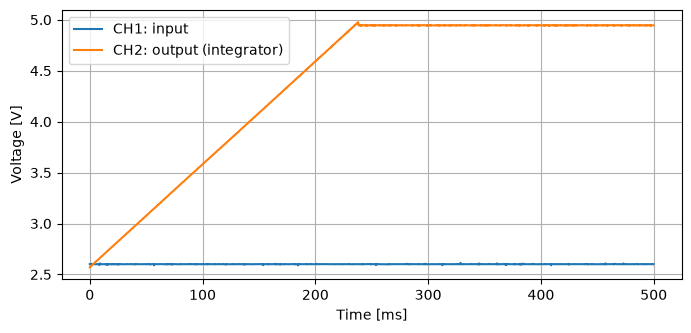

In [3]:
TAU_I = 10000   # integration time [us]

lab.fg.dc(2.6)
time.sleep(0.1)
reset_integrator(TAU_I)
t, ch1, ch2 = lab.scope.capture(2000, fs=4000)   # 0.5 s

ramp = (ch2 > 2.7) & (ch2 < 4.5)
slope = np.polyfit(t[ramp], ch2[ramp], 1)[0]
print(f"slope: {slope:.1f} V/s (theory {(ch1.mean() - 2.5) / (TAU_I * 1e-6):.1f} V/s)")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (integrator)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

理論の傾きは、実際の入力(CH1 の平均)から計算しています。

次に、入力をちょうど 2.5 V(Vref)にします。理屈では入力は 0 なので出力は動かないはずですが、信号発生器の 2.5 V と Mimic の Vref には数 mV の差があり、それも積み上がって出力がゆっくり動きます。1 秒取り込みます。

slope: 0.13 V/s -> an offset of 1.3 mV at the input


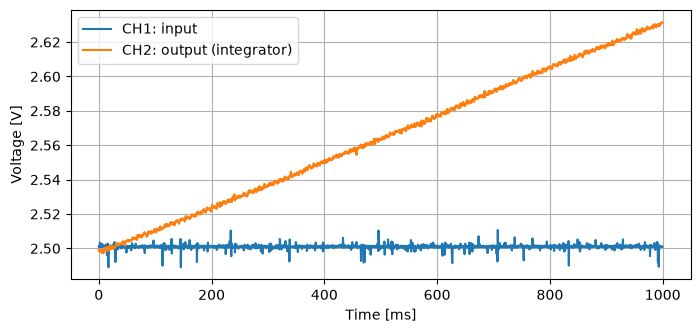

In [4]:
lab.fg.dc(2.5)
time.sleep(0.1)
reset_integrator(TAU_I)
t, ch1, ch2 = lab.scope.capture(2000, fs=2000)   # 1 s
slope = np.polyfit(t, ch2, 1)[0]
print(f"slope: {slope:.2f} V/s -> an offset of {slope * TAU_I * 1e-6 * 1e3:.1f} mV at the input")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (integrator)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

わずかなずれでも、時間がたつと積み上がります。実際の積分器でも、オペアンプのオフセット電圧や入力電流で同じことが起きます。これを防ぐのが**リーク**です。

## 実験 2:方形波を三角波にする

50 Hz、振幅 0.5 V の方形波を入れます。$\tau_i$ = 5 ms、リーク 100 ms にします。半周期(10 ms)のあいだ ±0.5 V を積分するので、出力は 0.5 V × 10 ms / 5 ms = **1 V** ずつ上がり下がりする三角波になるはずです。リークがあるので、出力は Vref のまわりにとどまります。

output: 2.006 - 3.005 V, peak to peak 0.999 V (ideal 1.0 V)


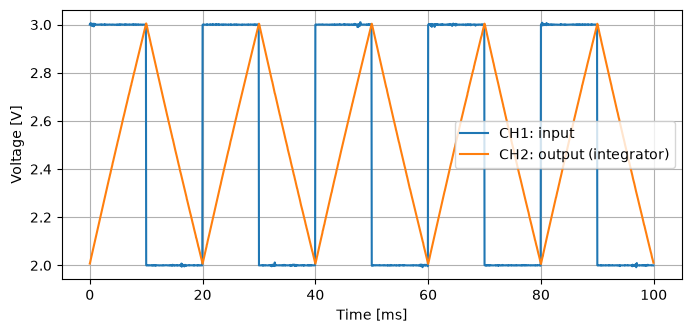

In [5]:
TAU_I = 5000     # [us]
LEAK = 100000    # [us]

lab.fg.square(50, 0.5)
reset_integrator(TAU_I, LEAK)
time.sleep(0.6)  # let the leak settle the centre
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
print(f"output: {ch2.min():.3f} - {ch2.max():.3f} V, peak to peak {ch2.max() - ch2.min():.3f} V (ideal 1.0 V)")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (integrator)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

リークがあるぶん、理想(1.0 V)よりわずかに小さくなります。

## 実験 3:ボード線図

$\tau_i$ = 1.59 ms($f_i$ = 100 Hz)、リーク 15.9 ms(低い周波数でのゲイン 10 倍、角の周波数 10 Hz)にして、周波数特性を測ります。ゲインは −20 dB/decade で下がり、100 Hz で 0 dB、位相は −90° に近いはずです。低い周波数ではゲインが大きいので、振幅は 0.2 V にします。

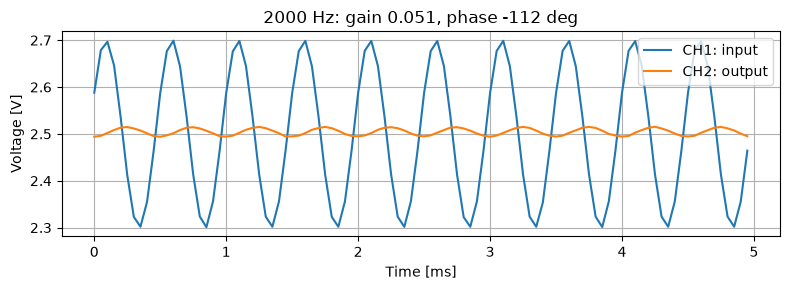

In [6]:
TAU_I, LEAK = 1592, 15915   # [us]
FI = 1e6 / (2 * np.pi * TAU_I)
L = LEAK / TAU_I
freqs = np.logspace(1, np.log10(2000), 16)
f_th = np.logspace(1, np.log10(2000), 200)

reset_integrator(TAU_I, LEAK)
r = lab.frequency_response(freqs, amp=0.2, monitor=True)

各周波数で取り込んだ波形です(クリックで開きます)。


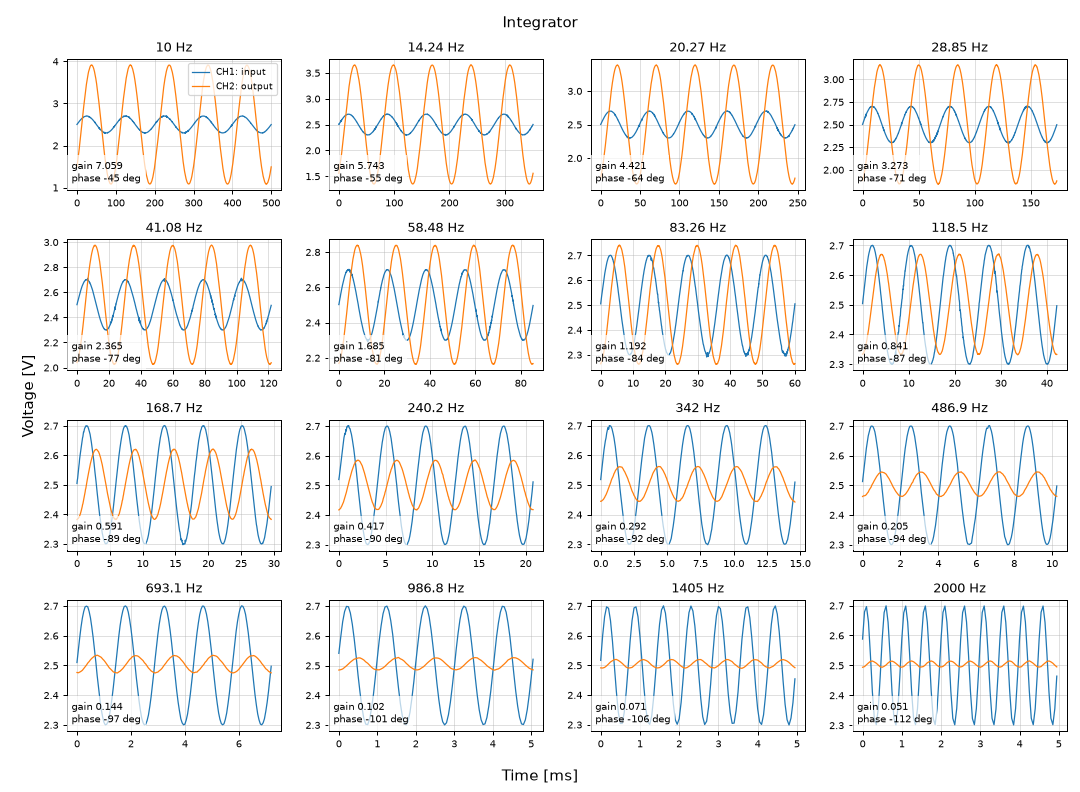

In [7]:
plot_waveforms(r, title="Integrator", collapsed=True)

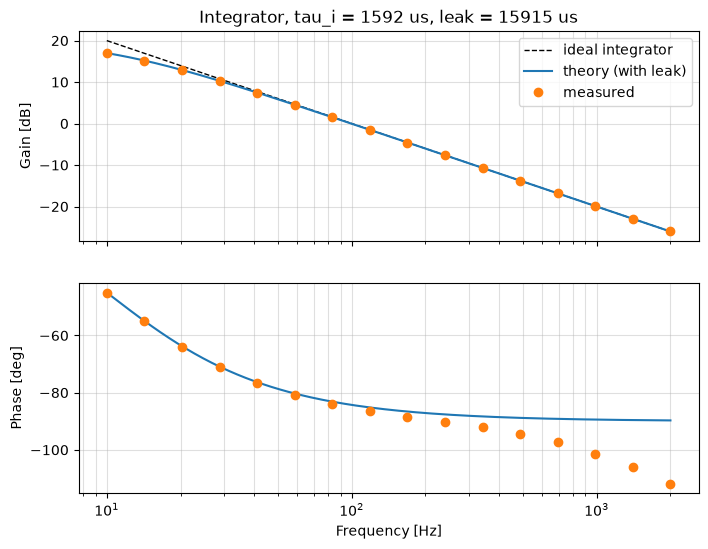

In [8]:
def h_integ(f):
    return L / (1 + 1j * L * f / FI)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.semilogx(f_th, 20 * np.log10(abs(1 / (1j * f_th / FI))), "k--", lw=1, label="ideal integrator")
ax1.semilogx(f_th, 20 * np.log10(abs(h_integ(f_th))), "-", label="theory (with leak)")
ax1.semilogx(r.freq, r.gain_db, "o", label="measured")
ax2.semilogx(f_th, np.degrees(np.angle(h_integ(f_th))), "-")
ax2.semilogx(r.freq, match_phase(r.phase, np.degrees(np.angle(h_integ(r.freq)))), "o")
ax1.set_title(f"Integrator, tau_i = {TAU_I} us, leak = {LEAK} us")
ax1.set_ylabel("Gain [dB]")
ax2.set_ylabel("Phase [deg]")
ax2.set_xlabel("Frequency [Hz]")
for ax in (ax1, ax2):
    ax.grid(True, which="both", alpha=0.4)
ax1.legend()
plt.show()

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 積分時間を変える

方形波を入れたまま、$\tau_i$ を変えて、三角波の大きさを見ます。
<details><summary>ヒント</summary>

`TAU_I` を 5000 → 2000 → 10000 と変えてみましょう。三角波の上り下りの幅は 0.5 V × 10 ms / $\tau_i$ で、1.0 V、2.5 V、0.5 V です。$\tau_i$ が短いほど、速く積み上がります。

</details>

peak to peak 2.494 V (ideal 2.500 V)


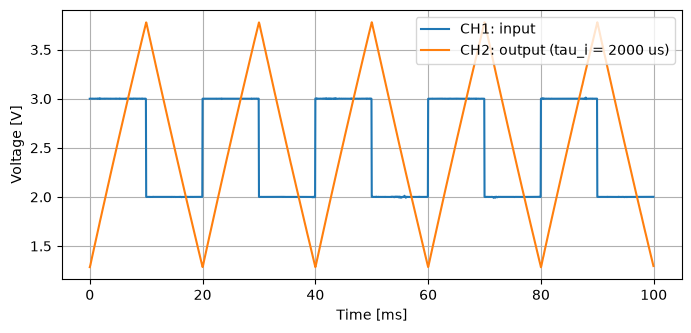

In [9]:
TAU_I = 2000   # [us]

lab.fg.square(50, 0.5)
reset_integrator(TAU_I, 100000)
time.sleep(0.6)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"peak to peak {ch2.max() - ch2.min():.3f} V (ideal {0.5 * 0.01 / (TAU_I * 1e-6):.3f} V)")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (tau_i = {TAU_I} us)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 2. リークを変える

$\tau_i$ = 5 ms のまま、リークの時定数を変えます。
<details><summary>ヒント</summary>

`LEAK` を 100000 → 20000 → 5000 → 0 と変えてみましょう。

- リークが短くなるほど、三角波の角が丸くなり、1 次の LPF の出力(方形波のなまり)に近づきます。5000(= $\tau_i$)では、ゲイン 1・$f_c$ = 32 Hz の LPF と同じです。
- 0(リークなし)では、入力のわずかな直流のずれが積み上がって、三角波ごとゆっくり上か下へ流れていき、やがて電源に張り付きます(何度か実行してみてください)。

</details>

output: 2.009 - 3.008 V


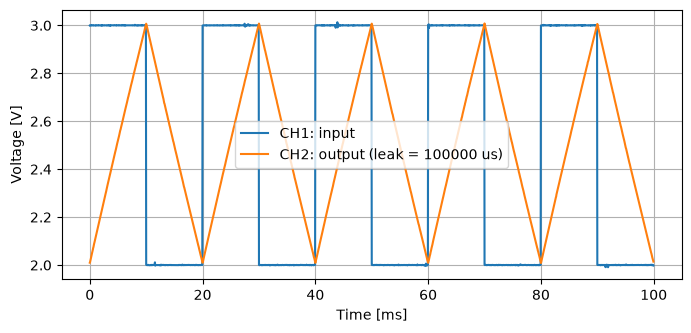

In [10]:
LEAK = 100000   # [us], 0: no leak

lab.fg.square(50, 0.5)
reset_integrator(5000, LEAK)
time.sleep(0.6)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"output: {ch2.min():.3f} - {ch2.max():.3f} V")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (leak = {LEAK} us)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 3. 三角波を積分する

三角波を入れると、出力はどんな形になるでしょうか。
<details><summary>ヒント</summary>

`TAU_I` を 5000 → 2000 と変えてみましょう。三角波を積分すると、放物線をつなげた形になり、**正弦波によく似た**波形になります。三角波は角があるだけで、ほとんど基本の周波数の正弦波でできている(高い周波数の成分が小さい)うえに、積分すると高い周波数の成分はさらに小さくなるからです。

</details>

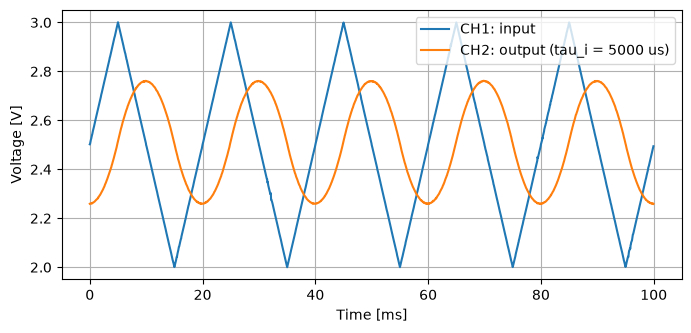

In [11]:
TAU_I = 5000   # [us]

lab.fg.triangle(50, 0.5)
reset_integrator(TAU_I, 100000)
time.sleep(0.6)
t, ch1, ch2 = lab.scope.capture(2000)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (tau_i = {TAU_I} us)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## まとめ

- 積分器は入力を時間で積み上げる。出力の傾きは 入力 / $\tau_i$($\tau_i = R_\mathrm{in}C$)。方形波は三角波になる。
- 周波数で見ると −20 dB/decade、位相 −90°。直流のゲインが無限大なので、わずかなずれも積み上がる。リーク($R_\mathrm{leak}$)で低い周波数のゲインを抑える。
- Mimic では `integrator(tau_i, leak)`(反転しない)。始め直すには、いったん別のモードにする。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [12]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()